In [57]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

batch_size = 128
latent_dim = 20
epochs = 20
lr = 1e-3
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

transform = transforms.ToTensor()
train_dataset = datasets.MNIST('./data',train=True,download=False,transform=transform)
train_loader = DataLoader(train_dataset,batch_size=batch_size,shuffle=True)

class VAE(nn.Module):
    def __init__(self,input_dim=784,hidden_dim=400,latent_dim=20):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim,hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim,latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim,latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim,hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim,input_dim),
            nn.Sigmoid(),
        )
    def encode(self,x):
        h = self.encoder(x)
        return self.fc_mu(h),self.fc_logvar(h)
    def reparameterize(self,mu,logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    def decode(self,z):
        return self.decoder(z)
    def forward(self,x):
        mu,logvar = self.encode(x)
        z = self.reparameterize(mu,logvar)
        return self.decode(z),mu,logvar
def loss_function(x_recon,x,mu,logvar):
    recon_loss = F.binary_cross_entropy(x_recon,x,reduction='sum')
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kld
model = VAE(latent_dim=latent_dim).to(device)
optimizer = optim.Adam(model.parameters(),lr=lr)
for epoch in range(1,epochs + 1):
    model.train()
    total_loss = 0
    for data,_ in train_loader:
        data = data.view(-1,784).to(device)
        optimizer.zero_grad()
        x_recon,mu,logvar = model(data)
        loss = loss_function(x_recon,data,mu,logvar)
        loss.backward()
        total_loss += loss.item()
        optimizer.step()
    avg_loss = total_loss / len(train_loader.dataset)
    print(f'Epoch {epoch:2d} | 平均损失:{avg_loss:.4f}')

Epoch  1 | 平均损失:165.5556
Epoch  2 | 平均损失:121.8980
Epoch  3 | 平均损失:115.1695
Epoch  4 | 平均损失:111.9946
Epoch  5 | 平均损失:110.1863
Epoch  6 | 平均损失:108.9553
Epoch  7 | 平均损失:108.0701
Epoch  8 | 平均损失:107.4080
Epoch  9 | 平均损失:106.8989
Epoch 10 | 平均损失:106.4822
Epoch 11 | 平均损失:106.0707
Epoch 12 | 平均损失:105.7551
Epoch 13 | 平均损失:105.4987
Epoch 14 | 平均损失:105.2188
Epoch 15 | 平均损失:104.9879
Epoch 16 | 平均损失:104.7643
Epoch 17 | 平均损失:104.5566
Epoch 18 | 平均损失:104.3983
Epoch 19 | 平均损失:104.2696
Epoch 20 | 平均损失:104.0923


C:\Users\yuhao.bian\AppData\Local\Temp\ipykernel_13752\2564550278.py:15: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yuhao.bian\AppData\Local\Temp\ipykernel_13752\2564550278.py:15: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yuhao.bian\AppData\Local\Temp\ipykernel_13752\2564550278.py:15: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\yuhao.bian\AppData\Local\Temp\ipykernel_13752\2564550278.py:15: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
d:\pythonprojects\practice-github\torch_final\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\pythonprojects\practice

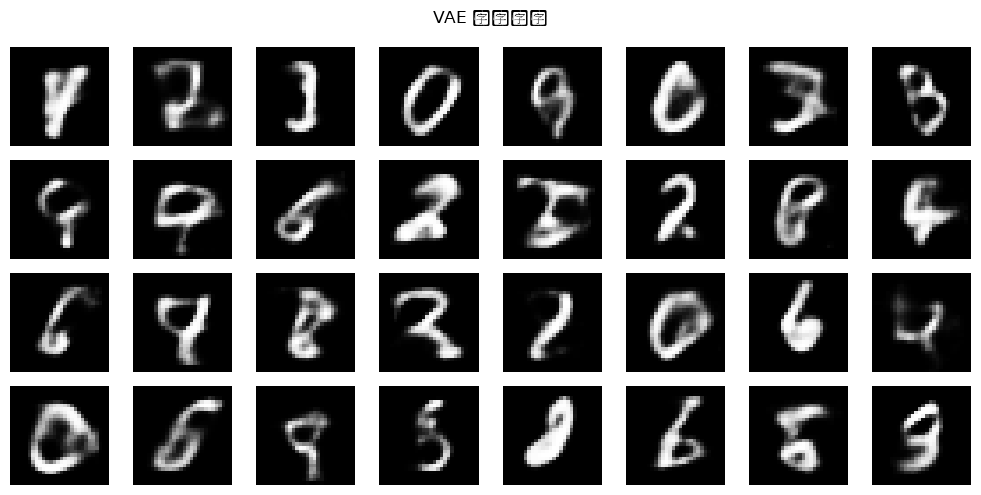

In [2]:
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    # 从标准正态先验 p(z) = N(0, I) 采样，直接生成新图像
    z = torch.randn(64, latent_dim).to(device)
    samples = model.decode(z).cpu().view(-1, 28, 28)

# 展示生成的图像
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i], cmap='gray')
    ax.axis('off')
plt.suptitle('VAE 生成样本')
plt.tight_layout()
plt.show()

# 也可以在隐空间插值，观察平滑过渡
with torch.no_grad():
    z1 = torch.randn(1, latent_dim).to(device)
    z2 = torch.randn(1, latent_dim).to(device)
    alphas = torch.linspace(0, 1, 10).unsqueeze(1).to(device)
    z_interp = z1 * (1 - alphas) + z2 * alphas
    interp_imgs = model.decode(z_interp).cpu().view(-1, 28, 28)


In [60]:
import pandas as pd
import numpy as np
df = pd.read_csv('data1/learn_pandas.csv',
                 usecols=['School','Grade','Name','Gender','Height','Test_Date'],
                 parse_dates=['Test_Date'],
                 na_values=['','N/A','无'],
                 nrows=100)
df.head(10)

,School,Grade,Name,Gender,Height,Test_Date
0,A,Freshman,Gaopeng Yang,Female,158.9,2019-10-05
1,B,Freshman,Changqiang You,Male,166.5,2019-09-04
2,A,Senior,Mei Sun,Male,188.9,2019-09-12
3,C,Sophomore,Xiaojuan Sun,Female,NaN,2020-01-03
4,C,Sophomore,Gaojuan You,Male,174.0,2019-11-06
5,D,Freshman,Xiaoli Qian,Female,158.0,2019-10-31
6,A,Freshman,Qiang Chu,Female,162.5,2019-12-12
7,D,Junior,Gaoqiang Qian,Female,161.9,2019-09-03
8,D,Freshman,Changli Zhang,Female,163.0,2020-01-05
9,B,Junior,Juan Xu,Female,164.8,2019-10-05


In [ ]:
df.to_csv("out.csv",index=False,encoding='utf-8-sig')
df.to_excel("out.xlsx",sheet_name="结果",index=False)
df.to_parquet("out.parquet",index=False)
with pd.ExcelWriter("多表导出.xlsx") as writer:
    df1.to_excel(writer,sheet_name="汇总",index=False)
    df2.to_excel(writer,sheet_name="明细",index=False)

In [62]:
print(df.head(10))
print(df.tail())
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
print(df.info(memory_usage="deep"))

  School      Grade            Name  Gender  Height  Test_Date
0      A   Freshman    Gaopeng Yang  Female   158.9 2019-10-05
1      B   Freshman  Changqiang You    Male   166.5 2019-09-04
2      A     Senior         Mei Sun    Male   188.9 2019-09-12
3      C  Sophomore    Xiaojuan Sun  Female     NaN 2020-01-03
4      C  Sophomore     Gaojuan You    Male   174.0 2019-11-06
5      D   Freshman     Xiaoli Qian  Female   158.0 2019-10-31
6      A   Freshman       Qiang Chu  Female   162.5 2019-12-12
7      D     Junior   Gaoqiang Qian  Female   161.9 2019-09-03
8      D   Freshman   Changli Zhang  Female   163.0 2020-01-05
9      B     Junior         Juan Xu  Female   164.8 2019-10-05
   School      Grade            Name  Gender  Height  Test_Date
95      D     Junior    Yanfeng Qian    Male   178.7 2019-11-23
96      B   Freshman   Changmei Feng  Female   163.8 2019-11-08
97      D  Sophomore   Xiaoqiang Qin  Female   160.8 2019-12-06
98      C  Sophomore    Xiaojuan Chu    Male     Na

In [63]:
print(df.describe())
print(df.describe(include='all'))
print(df['School'].value_counts())
print(df['School'].value_counts(normalize=True))

           Height            Test_Date
count   93.000000                  100
mean   164.291398  2019-11-05 04:19:12
min    147.300000  2019-09-03 00:00:00
25%    158.900000  2019-10-04 00:00:00
50%    163.100000  2019-11-05 00:00:00
75%    168.900000  2019-12-09 06:00:00
max    188.900000  2020-01-08 00:00:00
std      8.480933                  NaN
       School     Grade     Name  Gender      Height            Test_Date
count     100       100      100     100   93.000000                  100
unique      4         4       91       2         NaN                  NaN
top         D  Freshman  Mei Sun  Female         NaN                  NaN
freq       33        31        2      68         NaN                  NaN
mean      NaN       NaN      NaN     NaN  164.291398  2019-11-05 04:19:12
min       NaN       NaN      NaN     NaN  147.300000  2019-09-03 00:00:00
25%       NaN       NaN      NaN     NaN  158.900000  2019-10-04 00:00:00
50%       NaN       NaN      NaN     NaN  163.100000  201

In [32]:
print(df['Grade'].nunique())
print(df.isna().sum())
df.memory_usage(deep=True)

4
School       0
Grade        0
Name         0
Gender       0
Test_Date    0
dtype: int64


Index         132
School        900
Grade        1522
Name         1868
Gender       1336
Test_Date     800
dtype: int64

In [38]:
print(df['School'])
print(df[['School','Grade']])
print(df.loc[3,'Grade'])
print(df.iloc[0,2])
print(df.at[3,'School'])

0     A
1     B
2     A
3     C
4     C
     ..
95    D
96    B
97    D
98    C
99    B
Name: School, Length: 100, dtype: str
   School      Grade
0       A   Freshman
1       B   Freshman
2       A     Senior
3       C  Sophomore
4       C  Sophomore
..    ...        ...
95      D     Junior
96      B   Freshman
97      D  Sophomore
98      C  Sophomore
99      B   Freshman

[100 rows x 2 columns]
Sophomore
Gaopeng Yang
C


In [44]:
print(df.iat[0,2])
print(df.loc[10:20,['School','Grade']])
print(df[df['Gender'] == 'Male'])

Gaopeng Yang
   School      Grade
10      A   Freshman
11      D     Junior
12      A     Senior
13      A  Sophomore
14      D     Senior
15      C   Freshman
16      D     Junior
17      D     Junior
18      D     Senior
19      A     Senior
20      B     Junior
   School      Grade            Name Gender  Test_Date
1       B   Freshman  Changqiang You   Male 2019-09-04
2       A     Senior         Mei Sun   Male 2019-09-12
4       C  Sophomore     Gaojuan You   Male 2019-11-06
10      A   Freshman   Xiaopeng Zhou   Male 2019-09-29
16      D     Junior   Xiaoqiang Qin   Male 2019-09-11
17      D     Junior       Peng Wang   Male 2019-11-02
18      D     Senior    Xiaofeng Sun   Male 2019-11-04
21      A     Senior   Xiaopeng Shen   Male 2020-01-02
23      A     Senior     Qiang Zheng   Male 2019-12-05
24      D     Senior     Chunmei You   Male 2019-11-17
35      B   Freshman      Gaoli Zhao   Male 2019-10-08
36      B   Freshman    Xiaojuan Qin   Male 2019-12-10
38      B   Freshman

In [53]:
print(df.loc[(df['School'] == 'A') & (df['Gender'] == 'Male')])
print(df.loc[~df['School'].isin(['A','B'])])
df.query("Grade == 'Freshman' and School == 'A'")

   School      Grade           Name Gender  Test_Date
2       A     Senior        Mei Sun   Male 2019-09-12
10      A   Freshman  Xiaopeng Zhou   Male 2019-09-29
21      A     Senior  Xiaopeng Shen   Male 2020-01-02
23      A     Senior    Qiang Zheng   Male 2019-12-05
50      A     Junior    Xiaoli Wang   Male 2019-12-20
60      A   Freshman     Yanpeng Lv   Male 2019-11-17
71      A  Sophomore       Feng Han   Male 2019-10-25
   School      Grade             Name  Gender  Test_Date
3       C  Sophomore     Xiaojuan Sun  Female 2020-01-03
4       C  Sophomore      Gaojuan You    Male 2019-11-06
5       D   Freshman      Xiaoli Qian  Female 2019-10-31
7       D     Junior    Gaoqiang Qian  Female 2019-09-03
8       D   Freshman    Changli Zhang  Female 2020-01-05
11      D     Junior      Xiaoquan Lv  Female 2019-09-16
14      D     Senior     Xiaomei Zhou  Female 2019-12-29
15      C   Freshman  Changqiang Yang  Female 2020-01-01
16      D     Junior    Xiaoqiang Qin    Male 2019-09-1

,School,Grade,Name,Gender,Test_Date
0,A,Freshman,Gaopeng Yang,Female,2019-10-05
6,A,Freshman,Qiang Chu,Female,2019-12-12
10,A,Freshman,Xiaopeng Zhou,Male,2019-09-29
60,A,Freshman,Yanpeng Lv,Male,2019-11-17


In [71]:
print(df[df['School'].isin(['A','D'])].head(2))
print(df[df['Height'].between(160,180,inclusive='both')].head(2))

  School     Grade          Name  Gender  Height  Test_Date
0      A  Freshman  Gaopeng Yang  Female   158.9 2019-10-05
2      A    Senior       Mei Sun    Male   188.9 2019-09-12
  School      Grade            Name Gender  Height  Test_Date
1      B   Freshman  Changqiang You   Male   166.5 2019-09-04
4      C  Sophomore     Gaojuan You   Male   174.0 2019-11-06
